In [1]:
import copy
import matplotlib.cm as cm
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.integrate
import time
import pickle
import seaborn as sns
from scipy import stats
from scipy.stats import gaussian_kde

In [2]:
with open("../data/fig_6/all_H", "rb") as file:
    all_H = pickle.load(file)

with open("../data/fig_6/all_Q", "rb") as file:
    all_Q = pickle.load(file)

with open("../data/fig_6/all_t", "rb") as file:
    all_t = pickle.load(file)

with open("../data/fig_6/null_all_H", "rb") as file:
    null_all_H = pickle.load(file)

with open("../data/fig_6/null_all_Q", "rb") as file:
    null_all_Q = pickle.load(file)

with open("../data/fig_6/null_all_t", "rb") as file:
    null_all_t = pickle.load(file)

In [3]:
Z1 = pd.read_csv('../data/fig_6/Z1.csv', index_col=0)
Z2 = pd.read_csv('../data/fig_6/Z2.csv', index_col=0)
Z3 = pd.read_csv('../data/fig_6/Z3.csv', index_col=0)
Z4 = pd.read_csv('../data/fig_6/Z4.csv', index_col=0)

In [4]:
leak_areas = pd.read_csv('../data/fig_6/leak_areas.csv', index_col=0)['leak_area'].to_dict()
T = pd.to_datetime(pd.read_csv('../data/fig_6/timestamps.csv', index_col=0)['0'])
n2 = pd.read_csv(f'../data/fig_4_5/n2.csv', index_col=0)
n2.index = pd.to_datetime(n2.index)

In [5]:
all_H_0 = np.array([np.vstack(H) for H in all_H.values()])
all_Q_0 = np.array([np.vstack(Q) for Q in all_Q.values()])
all_t_0 = np.array([np.asarray(ti) for ti in all_t.values()])

# Conversion factor from CMS to GPM
cms_to_gpm = 15850.3

# Convert flow rates from CMS to GPM
all_Q_0 *= cms_to_gpm

H_0_01pct = np.percentile(all_H_0, 5, axis=0)
H_0_25pct = np.percentile(all_H_0, 25, axis=0)
H_0_75pct = np.percentile(all_H_0, 75, axis=0)
H_0_99pct = np.percentile(all_H_0, 95, axis=0)

Q_0_01pct = np.percentile(all_Q_0, 5, axis=0)
Q_0_25pct = np.percentile(all_Q_0, 25, axis=0)
Q_0_75pct = np.percentile(all_Q_0, 75, axis=0)
Q_0_99pct = np.percentile(all_Q_0, 95, axis=0)

In [6]:
null_all_H_0 = np.array([np.vstack(H) for H in null_all_H.values()])
null_all_Q_0 = np.array([np.vstack(Q) for Q in null_all_Q.values()])
null_all_t_0 = np.array([np.asarray(ti) for ti in null_all_t.values()])
null_all_Q_0 *= cms_to_gpm

null_H_0_01pct = np.percentile(null_all_H_0, 5, axis=0)
null_H_0_25pct = np.percentile(null_all_H_0, 25, axis=0)
null_H_0_75pct = np.percentile(null_all_H_0, 75, axis=0)
null_H_0_99pct = np.percentile(null_all_H_0, 95, axis=0)

null_Q_0_01pct = np.percentile(null_all_Q_0, 5, axis=0)
null_Q_0_25pct = np.percentile(null_all_Q_0, 25, axis=0)
null_Q_0_75pct = np.percentile(null_all_Q_0, 75, axis=0)
null_Q_0_99pct = np.percentile(null_all_Q_0, 95, axis=0)


In [7]:
# ============================================================
# Compute marginal evidence for M1 (leak) and M0 (no leak)
# at each timestep, then Bayes Factor BF10 = P(data|M1)/P(data|M0)
# ============================================================

npoints = 1000
xmin, xmax = 0., 1.2 * max(list(leak_areas.values()))
leak_range = np.linspace(xmin, xmax, npoints)

# Storage for per-timestep results
log_evidence_M1 = []  # log P(data | M1) at each t
log_evidence_M0 = []  # log P(data | M0) at each t
pdfs_M1 = []          # marginal leak area PDFs (for plotting)
logpdfs_M1 = []

t_start, t_end = 400, 1670
analysis_times = list(range(t_start, t_end))

for tt in analysis_times:
    # --- M1: KDE over (leak_area, H, Q) ---
    eval_pts_H_m1 = [1.42 * (all_H[trial][tt][1] - 0.6604 - 16/12*0.3048) for trial in all_H]
    eval_pts_Q_m1 = [60000. * (all_Q[trial][tt][0]) for trial in all_Q]
    observation_H = Z2.asof(all_t[0][tt]).loc['distinct']
    observation_Q = Z3.asof(all_t[0][tt]).loc['distinct']
    
    data_m1 = np.column_stack([list(leak_areas.values()), eval_pts_H_m1, eval_pts_Q_m1])
    kde_m1 = gaussian_kde(data_m1.T, bw_method='silverman')
    pts_m1 = np.vstack([leak_range,
                        np.repeat(observation_H, npoints),
                        np.repeat(observation_Q, npoints)])
    pdf_m1 = kde_m1.pdf(pts_m1)
    logpdf_m1 = kde_m1.logpdf(pts_m1)
    pdfs_M1.append(pdf_m1)
    logpdfs_M1.append(logpdf_m1)
    
    # Marginal evidence for M1: integrate P(data | leak_area) * P(leak_area) d(leak_area)
    evidence_m1 = np.trapz(pdf_m1, leak_range)
    log_evidence_M1.append(np.log10(evidence_m1 + 1e-300))
    
    # --- M0: KDE over (H, Q) only — no leak parameter ---
    eval_pts_H_m0 = [1.42 * (null_all_H[trial][tt][1] - 0.6604 - 16/12*0.3048) for trial in null_all_H]
    eval_pts_Q_m0 = [60000. * (null_all_Q[trial][tt][0]) for trial in null_all_Q]
    
    data_m0 = np.column_stack([eval_pts_H_m0, eval_pts_Q_m0])
    kde_m0 = gaussian_kde(data_m0.T, bw_method='silverman')
    pts_m0 = np.array([[observation_H], [observation_Q]])
    
    evidence_m0 = kde_m0.pdf(pts_m0).item()
    log_evidence_M0.append(np.log10(evidence_m0 + 1e-300))

log_evidence_M1 = np.array(log_evidence_M1)
log_evidence_M0 = np.array(log_evidence_M0)

# Bayes Factor (log scale)
log_BF10 = log_evidence_M1 - log_evidence_M0
BF_threshold = 10

print(f"Bayes Factor computed for timesteps {t_start}-{t_end}")
print(f"  Max log(BF10) = {log_BF10.max():.2f}")
print(f"  Min log(BF10) = {log_BF10.min():.2f}")


Bayes Factor computed for timesteps 400-1670
  Max log(BF10) = 11.54
  Min log(BF10) = -0.82


In [8]:
blues = sns.color_palette('YlGnBu', 6)

In [9]:
is_leak = np.zeros(len(log_BF10), dtype=bool)
is_leak[560:] = True

thresholds = np.linspace(-3, 15, 5000)
tprs = []
fprs = []
for threshold in thresholds:
    detected = log_BF10 > threshold

    tp = (detected & is_leak).sum()
    fn = (~detected & is_leak).sum()
    
    fp = (detected & ~is_leak).sum()
    tn = (~detected & ~is_leak).sum()
    
    tpr = tp / (tp + fn)
    fpr = fp / (fp + tn)

    tprs.append(tpr)
    fprs.append(fpr)

roc_results = pd.DataFrame(np.column_stack([thresholds, tprs, fprs]), columns=['threshold', 'tpr', 'fpr'])
auc = np.trapz(tprs[::-1], fprs[::-1])


*c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
*c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
*c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
*c* argument looks like a single numeric RGB or R

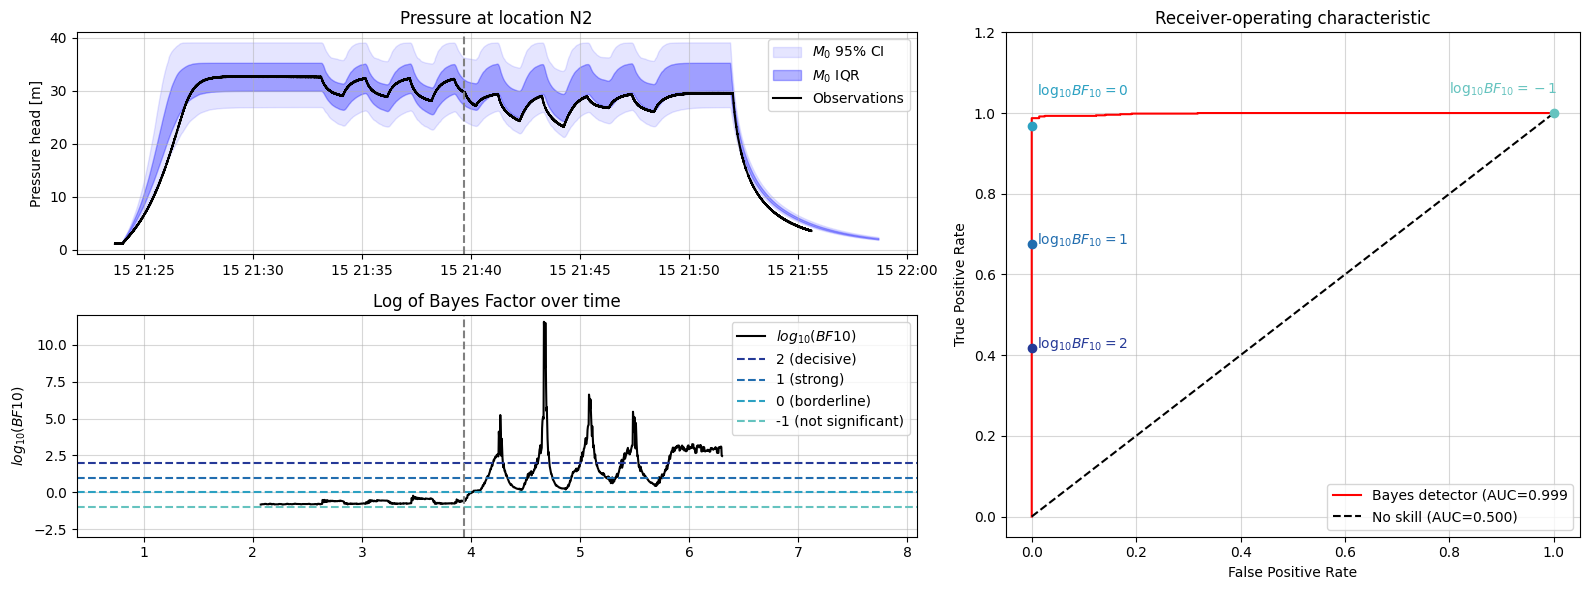

In [10]:
fig3 = plt.figure(constrained_layout=True, figsize=(16, 6))
gs = fig3.add_gridspec(2, 12)

ax1 = fig3.add_subplot(gs[0, :7])
ax1.fill_between(T.values, (null_H_0_99pct[:,1] - 0.6604 - 16/12*0.3048), (null_H_0_01pct[:,1] - 0.6604 - 16/12*0.3048), color='b', alpha=0.1, label='$M_0$ 95% CI')
ax1.fill_between(T.values, (null_H_0_75pct[:,1] - 0.6604 - 16/12*0.3048), (null_H_0_25pct[:,1] - 0.6604 - 16/12*0.3048), color='b', alpha=0.3, label='$M_0$ IQR')
# Set plot titles and labels
ax1.set_title('Pressure at location N2')
ax1.set_xlabel('Time (s)')
ax1.set_ylabel('Pressure head [m]')
# Add the sensor data
ax1.plot(n2.index.values, n2['distinct'].values / 1.42, label='Observations', color='black', linestyle='-')
ax1.axvline(pd.to_datetime('2024-11-15T21:39:40'), linestyle='--', c='0.5')
ax1.legend()
ax1.grid(alpha=0.5, zorder=-2)


ax2 = fig3.add_subplot(gs[1, :7])
ax2.plot(T.values[400:1670], log_BF10, label='$log_{10}(BF10)$', color='k')
ax2.axhline(2,  linestyle='--', color=blues[5], label='2 (decisive)')
ax2.axhline(1,  linestyle='--', color=blues[4],  label='1 (strong)')
ax2.axhline(0,  linestyle='--', color=blues[3],  label='0 (borderline)')
ax2.axhline(-1,  linestyle='--', color=blues[2],   label='-1 (not significant)')
leak_time = pd.to_datetime('2024-11-15T21:39:40')
ax2.axvline(leak_time,  linestyle='--', color='0.5')#, label='Actual leak start')
ax2.set_xlabel("time")
ax2.set_ylabel("$log_{10}(BF10)$")
ax2.legend()
ax2.grid(alpha=0.5, zorder=-2)
ax2.set_ylim(-3, 12)
ax2.set_xlabel('')
ax2.set_title('Log of Bayes Factor over time')
ax2.set_xlim(ax1.get_xlim())
ax2.xaxis.set_ticks(ax1.xaxis.get_ticklocs())
ax2.xaxis.set_ticklabels([1, 2, 3, 4, 5, 6, 7, 8])

ax3 = fig3.add_subplot(gs[:, 7:])
ax3.step(fprs, tprs, c='r', label=f'Bayes detector (AUC={auc:.3f}')
ax3.plot([0, 1], [0, 1], c='k', linestyle='--', label='No skill (AUC=0.500)')
ax3.grid(alpha=0.5, zorder=-2)
ax3.set_xlabel('False Positive Rate')
ax3.set_ylabel('True Positive Rate')
ax3.set_title('Receiver-operating characteristic')

tpr, fpr = roc_results.set_index('threshold').asof(-1).values
ax3.scatter([fpr], [tpr], c=blues[2], zorder=3)
ax3.annotate('$\log_{10} BF_{10} = -1$', [fpr-0.2, tpr+0.05], c=blues[2])

tpr, fpr = roc_results.set_index('threshold').asof(0).values
ax3.scatter([fpr], [tpr], c=blues[3], zorder=3)
ax3.annotate('$\log_{10} BF_{10} = 0$', [fpr+0.01, tpr+0.075], c=blues[3])

tpr, fpr = roc_results.set_index('threshold').asof(1).values
ax3.scatter([fpr], [tpr], c=blues[4], zorder=3)
ax3.annotate('$\log_{10} BF_{10} = 1$', [fpr+0.01, tpr], c=blues[4])

tpr, fpr = roc_results.set_index('threshold').asof(2).values
ax3.scatter([fpr], [tpr], c=blues[5], zorder=3)
ax3.annotate('$\log_{10} BF_{10} = 2$', [fpr+0.01, tpr], c=blues[5])

ax3.set_ylim(-0.05, 1.2)
ax3.legend(loc=4)

ax1.set_xlabel('')

plt.tight_layout()
